In [1]:
# Run in terminal:
#uv init
#uv add --dev ipykernel jupyter
#uv sync

In [2]:
!uv pip install -q osmnx networkx "geopandas[all]" pyrosm lonboard

In [29]:
import osmnx as ox
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import lonboard as lb
from pyrosm import OSM
from pathlib import Path
import pandas as pd

# Suppress warnings to keep output clean
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# Download MTC Bart Station Data, convert to GeoJSON format
bart_stations_url = 'https://services3.arcgis.com/i2dkYWmb4wHvYPda/arcgis/rest/services/BART_Stations/FeatureServer/0'

bart_stations = gpd.read_file(
    f"{bart_stations_url}/query"
    "?where=1%3D1"
    "&outFields=*"
    "&returnGeometry=true"
    "&f=geojson"
)

bart_stations.to_file(
    "../data/raw/bart_stations.geojson",
    driver="GeoJSON"
)

In [73]:
bart_stations = gpd.read_file("../data/raw/bart_stations.geojson")
print(bart_stations.head())

bart_stations_proj = ox.projection.project_gdf(bart_stations)

dtberkeley_station = bart_stations[bart_stations['Station_Name'] == 'Downtown Berkeley']
dtberkeley_station_geom = dtberkeley_station.iloc[0].geometry
dtberkeley_station_projected_geom = bart_stations_proj[bart_stations_proj['Station_Name'] == 'Downtown Berkeley'].iloc[0].geometry

   OBJECTID              Station_Name  In_CEJS  In_EPA_IRA  In_EPC  \
0         1                  Milpitas        1           1       0   
1         2  Berryessa/North San Jose        0           1       0   
2         3     Civic Center/UN Plaza        0           0       1   
3         4                   Concord        0           0       0   
4         5                     Colma        1           1       0   

   Total_Disadvantaged                     geometry  
0                    2  POINT (-121.89109 37.41028)  
1                    1  POINT (-121.87469 37.36848)  
2                    1  POINT (-122.41394 37.77939)  
3                    0  POINT (-122.02906 37.97382)  
4                    2  POINT (-122.46622 37.68462)  


In [17]:
#Create OSM graphs for each of the BART station areas - example: Downtown Berkeley
downtownberkeley_walk = ox.graph_from_point((dtberkeley_station_geom.y, dtberkeley_station_geom.x), dist=2000, network_type='walk')
downtownberkeley_drive = ox.graph_from_point((dtberkeley_station_geom.y, dtberkeley_station_geom.x), dist=8000, network_type='drive')


In [19]:
# Project graphs to local UTM zones
downtownberkeley_walk_proj = ox.project_graph(downtownberkeley_walk)
downtownberkeley_drive_proj = ox.project_graph(downtownberkeley_drive)

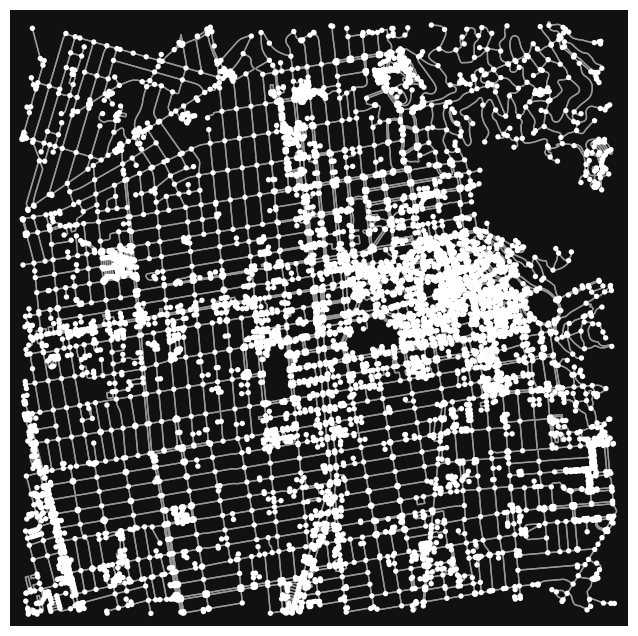

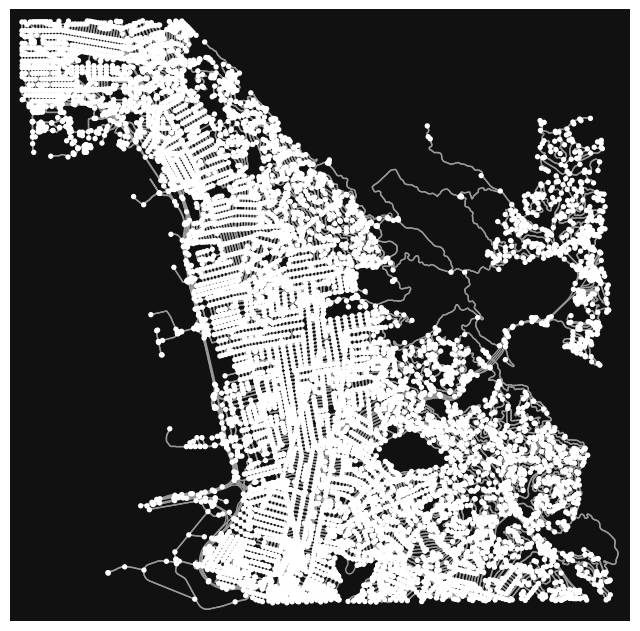

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>)

In [20]:
ox.plot.plot_graph(downtownberkeley_walk_proj)
ox.plot.plot_graph(downtownberkeley_drive_proj)

In [ ]:
# Find nearest network nodes
walk_station_node = ox.distance.nearest_nodes(
    downtownberkeley_walk_proj,
    X=dtberkeley_station_projected_geom.x,
    Y=dtberkeley_station_projected_geom.y
)

drive_station_node = ox.distance.nearest_nodes(
    downtownberkeley_drive_proj,
    X=dtberkeley_station_projected_geom.x,
    Y=dtberkeley_station_projected_geom.y
)

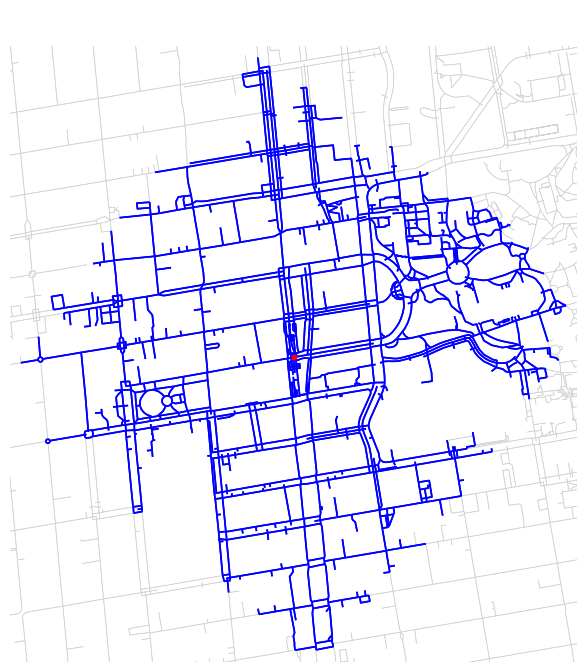

In [91]:
# Set max walking distance (1/2 mile), converted to meters
walk_distance = 0.5 * 1609.34  # 1/2 mile in meters

walk_reachable_nodes = nx.single_source_dijkstra_path_length(
    downtownberkeley_walk_proj,
    walk_station_node,
    cutoff=walk_distance,
    weight="length"
)

# Extract reachable node IDs
reachable_node_ids = list(walk_reachable_nodes.keys())

# Create reachable subgraph
reachable_graph = downtownberkeley_walk_proj.subgraph(
    reachable_node_ids
).copy()

# Plot full network as background
fig, ax = ox.plot_graph(
    downtownberkeley_walk_proj,
    node_size=0,
    edge_color="lightgray",
    edge_linewidth=0.5,
    bgcolor="white",
    show=False,
    close=False
)

# Overlay reachable network
ox.plot_graph(
    reachable_graph,
    ax=ax,
    node_size=0,
    edge_color="blue",
    edge_linewidth=1.2,
    show=False,
    close=False
)

bart_stations_proj.plot(ax=ax, color="red", markersize=10)

ax.set_title("Downtown Berkeley BART Station -  1/2 Mile Walking Network", color = 'white')
plt.savefig("../visualizations/dtberkeley_1_2_mile_walking_network.png", bbox_inches="tight")
plt.show()

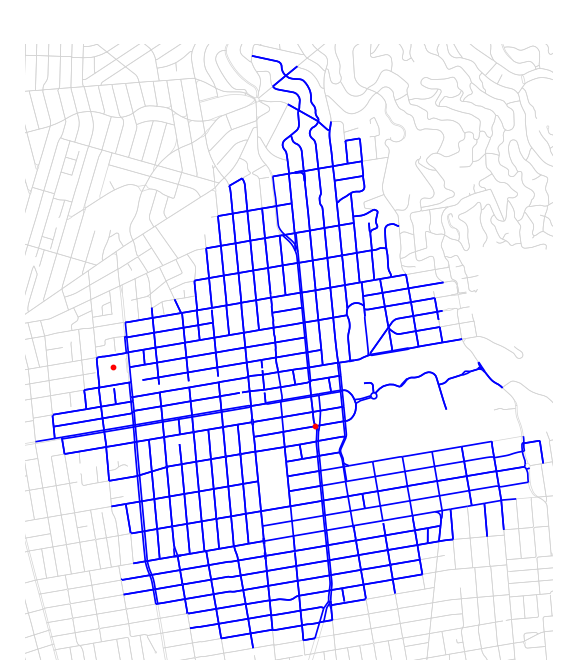

In [90]:
# Set max drive time (minutes)
drive_time = 15

drive_reachable_nodes = nx.single_source_dijkstra_path_length(
    downtownberkeley_drive_proj,
    drive_station_node,
    cutoff=drive_time,
    weight="travel_time"
)

# Extract reachable node IDs
reachable_node_ids = list(drive_reachable_nodes.keys())

# Create reachable subgraph
reachable_graph = downtownberkeley_drive_proj.subgraph(
    reachable_node_ids
).copy()

# Plot full network as background
fig, ax = ox.plot_graph(
    downtownberkeley_drive_proj,
    node_size=0,
    edge_color="lightgray",
    edge_linewidth=0.5,
    bgcolor="white",
    show=False,
    close=False
)

# Overlay reachable network
ox.plot_graph(
    reachable_graph,
    ax=ax,
    node_size=0,
    edge_color="blue",
    edge_linewidth=1.2,
    show=False,
    close=False
)

bart_stations_proj.plot(ax=ax, color="red", markersize=10)

ax.set_title("Downtown Berkeley BART Station - 15 Minute Drive Time Network", color = 'white')
plt.savefig("../visualizations/dtberkeley_15_minute_drive_network.png", bbox_inches="tight")
plt.show()

In [27]:
CRS = "EPSG:26910"

COUNTY_NAMES = {"001": "Alameda", "013": "Contra Costa", "075": "San Francisco",
                "081": "San Mateo", "085": "Santa Clara"}

def load_block_groups():
    block_groups = gpd.read_file("../data/raw/tl_2023_06_bg/tl_2023_06_bg.shp")
    before = len(block_groups)

    block_groups = block_groups[block_groups["COUNTYFP"].isin(list(COUNTY_NAMES.keys()))]
    #log_step("block groups", "keep the 5 counties", before, len(block_groups),
    #         "only the BART counties are in our study area")

    before = len(block_groups)
    block_groups = block_groups[block_groups["ALAND"] > 0]
    #log_step("block groups", "drop block groups with no land", before, len(block_groups),
    #         "water-only block groups have no jobs")

    block_groups = block_groups.to_crs(CRS)
    block_groups["county"] = block_groups["COUNTYFP"].map(COUNTY_NAMES)
    block_groups = block_groups[["GEOID", "county", "geometry"]]
    return block_groups.reset_index(drop=True)

block_groups = load_block_groups()
block_groups.head()

,GEOID,county,geometry
0,060133451021,Contra Costa,"POLYGON ((591892.843 4178308.211, 591901.427 4..."
1,060133551151,Contra Costa,"POLYGON ((596174.067 4179759.561, 596181.345 4..."
2,060133072023,Contra Costa,"POLYGON ((602266.804 4207101.707, 602278.059 4..."
3,060014423012,Alameda,"POLYGON ((591290.504 4154204.041, 591291.082 4..."
4,060133592043,Contra Costa,"POLYGON ((563063.06 4206168.242, 563079.598 42..."


In [47]:
od_data = pd.read_csv('../data/raw/lodes/ca_od_main_JT00_2023.csv.gz',
    dtype={
        "h_geocode": str,
        "w_geocode": str
    }
    )
od_data.head()

# Convert OD geocodes from block to block group level
od_data_blkgrp = od_data.copy()
od_data_blkgrp['h_block_group'] = od_data_blkgrp['h_geocode'].str[:12]
od_data_blkgrp['w_block_group'] = od_data_blkgrp['w_geocode'].str[:12]
print(len(od_data_blkgrp))

# Filter to only OD pairs with both both home and work places in Bay Area counties
od_data_blkgrp_filtered = od_data_blkgrp[od_data_blkgrp['h_block_group'].str[2:5].isin(list(COUNTY_NAMES.keys())) & od_data_blkgrp['w_block_group'].str[2:5].isin(list(COUNTY_NAMES.keys()))]
print(len(od_data_blkgrp_filtered))
od_data_blkgrp_filtered.head()

16241068
2420324


,w_geocode,h_geocode,S000,SA01,SA02,SA03,SE01,SE02,SE03,SI01,SI02,SI03,createdate,h_block_group,w_block_group
0,060014001001003,060014001002002,1,0,0,1,0,0,1,0,0,1,20251202,060014001002,060014001001
1,060014001001003,060014001002018,1,0,0,1,0,0,1,0,0,1,20251202,060014001002,060014001001
2,060014001001003,060014008001013,1,0,1,0,0,0,1,0,0,1,20251202,060014008001,060014001001
3,060014001001003,060014010001004,1,0,1,0,0,0,1,0,0,1,20251202,060014010001,060014001001
4,060014001001003,060014016001025,1,0,0,1,0,0,1,0,0,1,20251202,060014016001,060014001001


In [48]:
# Load block group population weighted centroid data (used to get a more accurate cutoff for network analysis)
blkgrp_centroids = pd.read_csv('../data/raw/CenPop2020_Mean_BG06.txt',
    dtype={
       "STATEFP": str,
        "COUNTYFP": str,
        "TRACTCE": str,
        "BLKGRPCE": str
    }
)

# Create block group code field, then filter to necessary columns
blkgrp_centroids['GEOID'] = blkgrp_centroids['STATEFP'] + blkgrp_centroids['COUNTYFP'] + blkgrp_centroids['TRACTCE'] + blkgrp_centroids['BLKGRPCE']
blkgrp_centroids_selected = blkgrp_centroids[['GEOID', 'POPULATION', 'LATITUDE', 'LONGITUDE']]
blkgrp_centroids_selected.head()

,GEOID,POPULATION,LATITUDE,LONGITUDE
0,060014001001,1789,37.861461,-122.234285
1,060014001002,1249,37.855979,-122.224707
2,060014002001,1022,37.849892,-122.248571
3,060014002002,979,37.846618,-122.250574
4,060014003001,1123,37.843653,-122.248773


In [49]:
# Merge block group geometry files with centroid data
blkgrp_merged = block_groups.merge(blkgrp_centroids_selected, on='GEOID', how='left')
blkgrp_merged

,GEOID,county,geometry,POPULATION,LATITUDE,LONGITUDE
0,060133451021,Contra Costa,"POLYGON ((591892.843 4178308.211, 591901.427 4...",1285,37.742002,-121.949219
1,060133551151,Contra Costa,"POLYGON ((596174.067 4179759.561, 596181.345 4...",1880,37.762750,-121.905663
2,060133072023,Contra Costa,"POLYGON ((602266.804 4207101.707, 602278.059 4...",1893,38.004889,-121.829747
3,060014423012,Alameda,"POLYGON ((591290.504 4154204.041, 591291.082 4...",1193,37.529815,-121.961151
4,060133592043,Contra Costa,"POLYGON ((563063.06 4206168.242, 563079.598 42...",2346,37.998560,-122.268879
...,...,...,...,...,...,...
4186,060133361041,Contra Costa,"POLYGON ((584058.172 4203013.721, 584087.774 4...",1433,37.969840,-122.041170
4187,060133040073,Contra Costa,"POLYGON ((619439.513 4196983.645, 619436.198 4...",1495,37.914525,-121.617325
4188,060133551153,Contra Costa,"POLYGON ((595345.33 4180078.949, 595423.576 41...",5747,37.761612,-121.911863
4189,060133462052,Contra Costa,"POLYGON ((589728.385 4190386.537, 589729.088 4...",1323,37.852908,-121.968476


In [50]:
# Create centroid dataframes for home and work blockgroups, rename before merging with OD data
w_blkgrps = blkgrp_centroids_selected[['GEOID', 'LATITUDE', 'LONGITUDE']].rename(columns={'LATITUDE': 'w_latitude', 'LONGITUDE': 'w_longitude'})
h_blkgrps = blkgrp_centroids_selected[['GEOID', 'LATITUDE', 'LONGITUDE']].rename(columns={'LATITUDE': 'h_latitude', 'LONGITUDE': 'h_longitude'})

# Merge OD data
od_merged = od_data_blkgrp.merge(h_blkgrps, left_on='h_block_group', right_on='GEOID', how='left').drop(columns=['GEOID'])
od_merged = od_merged.merge(w_blkgrps, left_on='w_block_group', right_on='GEOID', how='left').drop(columns=['GEOID'])
od_merged.head()


,w_geocode,h_geocode,S000,SA01,SA02,SA03,SE01,SE02,SE03,SI01,SI02,SI03,createdate,h_block_group,w_block_group,h_latitude,h_longitude,w_latitude,w_longitude
0,060014001001003,060014001002002,1,0,0,1,0,0,1,0,0,1,20251202,060014001002,060014001001,37.855979,-122.224707,37.861461,-122.234285
1,060014001001003,060014001002018,1,0,0,1,0,0,1,0,0,1,20251202,060014001002,060014001001,37.855979,-122.224707,37.861461,-122.234285
2,060014001001003,060014008001013,1,0,1,0,0,0,1,0,0,1,20251202,060014008001,060014001001,37.848123,-122.284989,37.861461,-122.234285
3,060014001001003,060014010001004,1,0,1,0,0,0,1,0,0,1,20251202,060014010001,060014001001,37.835827,-122.270566,37.861461,-122.234285
4,060014001001003,060014016001025,1,0,0,1,0,0,1,0,0,1,20251202,060014016001,060014001001,37.817627,-122.279681,37.861461,-122.234285
